# Module 4 Homework (2026 Cohort) — Trading Strategy & Simulation

Base: [2026 Module 4 Colab](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/04-trading-strategy-and-simulation/%5B2026%5D_Module_04_Colab_Trading_Simulations.ipynb).

This notebook reproduces the Module 4 workbook and solves Q1–Q4:

- **Q1** – keep fewer dummies (drop `Ticker` and `month_wom`): 208 features instead of 301, then get the CAGR of `pred10_rf_best_rule_55`.
- **Q2** – build the `tpr_fpr_dataframe` for the Random Forest and test decision rules `0.56 … 0.64`; pick the best rule with **< 5 average trades per day**.
- **Q3** – redefine the target to `growth_future_30d > 1.022` and count the trades of `pred5_clf_10`.
- **Q4** – [EXPLORATORY] describe an ideal trading strategy.

Data: same combined parquet used in Module 3. If it is not found locally, it is downloaded from Google Drive.

Homework statement: [cohorts/2026/homework4.md](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/cohorts/2026/homework4.md).

In [1]:
import os
import gc
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, accuracy_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 120)

RANDOM_STATE = 42

In [2]:
%matplotlib inline

## 0) Load the combined dataframe

In [3]:
FILENAME = 'stocks_df_combined_2026_09_18.parquet.brotli'
GDRIVE_ID = '1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5'

CANDIDATES = [
    FILENAME,
    os.path.join('03-the model', FILENAME),
    os.path.join('..', '03-the model', FILENAME),
    os.path.join('/content', FILENAME),
]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    import gdown
    DATA_PATH = FILENAME
    gdown.download(id=GDRIVE_ID, output=DATA_PATH, quiet=False)

df_full = pd.read_parquet(DATA_PATH)
print('Using:', DATA_PATH)
print('df_full:', df_full.shape)
print('Date range:', df_full.Date.min().date(), '->', df_full.Date.max().date())
print('Tickers:', df_full.Ticker.nunique())

Using: ..\03-the model\stocks_df_combined_2026_09_18.parquet.brotli
df_full: (240759, 203)
Date range: 1972-06-01 -> 2026-09-18
Tickers: 33


## 0.1) Variable sets and feature engineering (identical to the Colab)

`OHLCV` uses `Close_x` because the combined parquet has `Close_x`/`Close_y` (the `Adj Close_x` column does not exist).

In [4]:
# growth indicators (but not future growth)
GROWTH = [g for g in df_full.keys() if (g.find('growth_') == 0) & (g.find('future') < 0)]

# leaving only Volume ==> generate ln(Volume)
OHLCV = ['Open', 'High', 'Low', 'Close_x', 'Volume']

CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type']

TO_PREDICT = [g for g in df_full.keys() if (g.find('future') >= 0)]

TO_DROP = ['Year', 'Date', 'index_x', 'index_y', 'index', 'Quarter', 'Close_y',
           'Dividends', 'Stock Splits'] + CATEGORICAL + OHLCV

print('Growth features:', len(GROWTH))
print('Targets (future):', TO_PREDICT)

Growth features: 54
Targets (future): ['growth_future_30d', 'is_positive_growth_30d_future']


In [5]:
# custom numerical features
df_full['ln_volume'] = np.log(df_full['Volume'] + 1e-6)
df_full['div_payout'] = (df_full['Dividends'] > 0).astype(int)
df_full['stock_split'] = (df_full['Stock Splits'] > 0).astype(int)

CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative',
                    'volatility', 'ln_volume', 'div_payout', 'stock_split']

In [6]:
TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1', 'aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo', 'dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl') >= 0]

MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
         'DGS1', 'DGS5', 'DGS10']

NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

print('Technical patterns:', len(TECHNICAL_PATTERNS))
print('Numerical features:', len(NUMERICAL))

Technical patterns: 61
Numerical features: 186


In [7]:
# 25 years of data (from 2000)
df = df_full[df_full.Date >= '2000-01-01'].copy()

# Month name and weekday as strings (same as the Module 4 workbook)
df['Month'] = pd.to_datetime(df['Month'], format='%m').dt.strftime('%B')
df['Weekday'] = df['Weekday'].astype(str)

# week of month: 1..5, combined with the month name  ->  e.g. 'October_w1'
df['wom'] = ((df['Date'].dt.day - 1) // 7 + 1).astype(str)
df['month_wom'] = df['Month'] + '_w' + df['wom']
del df['wom']

print('df:', df.shape)
print('Tickers:', df.Ticker.nunique())
print('Weekday values:', sorted(df.Weekday.unique()))
print('month_wom examples:', df.month_wom.value_counts().index[:3].tolist())

df: (202292, 207)
Tickers: 33
Weekday values: ['0', '1', '2', '3', '4', '5', '6']
month_wom examples: ['August_w1', 'July_w4', 'August_w4']


## 0.2) Helpers: temporal split, cleaning, trading simulation, TPR/FPR

The trading simulation follows the Colab exactly: invest **$100** on every positive prediction, hold 30 days, pay **0.2%** round-trip fees. Capital is `100 * 30 * Q75(daily investments)` and CAGR is computed over the 4-year TEST period.

In [8]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15):
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)
    labels = []
    for date in df['Date']:
        if date <= train_end:
            labels.append('train')
        elif date <= val_end:
            labels.append('validation')
        else:
            labels.append('test')
    df['split'] = labels
    return df

In [9]:
def clean_dataframe_from_inf_and_nan(df):
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)
    return df

In [10]:
def run_simulation(df, pred):
    '''$100 per positive prediction on TEST. Returns the same metrics as df_sim1_results.'''
    prefix = pred.split('_')[0]

    gross_rev_vector = df[pred] * 100 * (df['growth_future_30d'] - 1)
    fees_vector = -df[pred] * 100 * 0.002
    net_rev_vector = gross_rev_vector + fees_vector

    mask = (df['split'] == 'test') & (df[pred] == 1)

    trades = int(mask.sum())
    gross_rev = float(gross_rev_vector[mask].sum())
    fees = float(fees_vector[mask].sum())
    net_rev = float(net_rev_vector[mask].sum())

    daily = df.loc[mask].groupby('Date')[pred].count()
    avg_inv_per_day = float(daily.mean()) if len(daily) else 0.0
    q75_inv_per_day = float(daily.quantile(0.75)) if len(daily) else 0.0

    capital = 100.0 * 30.0 * q75_inv_per_day
    CAGR = ((capital + net_rev) / capital) ** (1 / 4) if capital > 0 else np.nan

    return {
        'prediction': pred,
        'trades': trades,
        'gross_rev': gross_rev,
        'fees': fees,
        'net_rev': net_rev,
        'avg_inv_per_day': avg_inv_per_day,
        'q75_inv_per_day': q75_inv_per_day,
        'capital': capital,
        'CAGR': CAGR,
    }

In [11]:
def tpr_fpr_dataframe(y_true, y_pred, only_even=False):
    scores = []
    thresholds = np.linspace(0, 1, 51) if only_even else np.linspace(0, 1, 101)

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    for t in thresholds:
        actual_positive = y_true == 1
        actual_negative = y_true == 0
        predict_positive = y_pred >= t
        predict_negative = y_pred < t

        tp = int(np.sum(predict_positive & actual_positive))
        tn = int(np.sum(predict_negative & actual_negative))
        fp = int(np.sum(predict_positive & actual_negative))
        fn = int(np.sum(predict_negative & actual_positive))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1_score = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        accuracy = (tp + tn) / (tp + tn + fp + fn)

        scores.append((t, tp, fp, fn, tn, precision, recall, accuracy, f1_score))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'accuracy', 'f1_score']
    df_scores = pd.DataFrame(scores, columns=columns)
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    return df_scores

## Question 1: Less Features is More

Drop `Ticker` and `month_wom` from the categorical set **before** generating dummies. The feature matrix must go from **301 to 208** features (about 31% fewer). Then run the whole pipeline and read the CAGR of `pred10_rf_best_rule_55`.

In [12]:
# Fewer dummies: only Month, Weekday and ticker_type (no Ticker, no month_wom)
CATEGORICAL_SHORT = ['Month', 'Weekday', 'ticker_type']

dummy_variables = pd.get_dummies(df[CATEGORICAL_SHORT], dtype='int32')
DUMMIES = dummy_variables.keys().to_list()

df_with_dummies = pd.concat([df, dummy_variables], axis=1)

print('Dummy variables:', len(DUMMIES))
print('Total features NUMERICAL+DUMMIES:', len(NUMERICAL + DUMMIES), '(expected 208)')

Dummy variables: 22
Total features NUMERICAL+DUMMIES: 208 (expected 208)


In [13]:
new_df = df_with_dummies.copy()

# hand rules from the Colab
new_df['pred0_manual_cci'] = (new_df.cci > 200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d > 1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df.growth_30d > 1) & (new_df.growth_snp500_30d > 1)).astype(int)
new_df['pred3_manual_dgs10_5'] = ((new_df.DGS10 <= 4.5) & (new_df.DGS5 <= 4)).astype(int)
new_df['pred4_manual_dgs10_fedfunds'] = ((new_df.DGS10 > 4) & (new_df.FEDFUNDS <= 4.795)).astype(int)

new_df = temporal_split(new_df, new_df.Date.min(), new_df.Date.max())

print('Split counts:', new_df.split.value_counts().to_dict())
print('Split dates:')
print(new_df.groupby('split')['Date'].agg(['min', 'max']))

Split counts: {'train': 136842, 'test': 33163, 'validation': 32287}
Split dates:
                  min        max
split                           
test       2022-09-16 2026-09-18
train      2000-01-03 2018-09-13
validation 2018-09-14 2022-09-15


In [14]:
features_list = NUMERICAL + DUMMIES
to_predict = 'is_positive_growth_30d_future'

train_valid_df = new_df[new_df.split.isin(['train', 'validation'])].copy(deep=True)

X_train_valid = clean_dataframe_from_inf_and_nan(train_valid_df[features_list + [to_predict]].copy(deep=True))
X_all = clean_dataframe_from_inf_and_nan(new_df[features_list + [to_predict]].copy(deep=True))

y_train_valid = X_train_valid[to_predict]
y_all = X_all[to_predict]
del X_train_valid[to_predict]
del X_all[to_predict]

print('X_train_valid:', X_train_valid.shape)
print('X_all:', X_all.shape)

X_train_valid: (169129, 208)
X_all: (202292, 208)


In [15]:
# The 2026 workbook hard-codes the best models: DT depth 7 and RF 100 trees / depth 13
clf_best = DecisionTreeClassifier(max_depth=7, random_state=RANDOM_STATE)
clf_best.fit(X_train_valid, y_train_valid)

rf_best = RandomForestClassifier(n_estimators=100, max_depth=13,
                                 random_state=RANDOM_STATE, n_jobs=-1)
rf_best.fit(X_train_valid, y_train_valid)

print('Decision Tree (depth 7) and Random Forest (100, depth 13) trained.')

Decision Tree (depth 7) and Random Forest (100, depth 13) trained.


In [16]:
# Decision Tree rules: pred8 (0.56) and pred9 (0.66)
clf_proba = np.array([k[1] for k in clf_best.predict_proba(X_all)])
new_df['proba_clf_best'] = clf_proba
new_df['pred8_clf_second_best_rule_56'] = (clf_proba >= 0.56).astype(int)
new_df['pred9_clf_second_best_rule_66'] = (clf_proba >= 0.66).astype(int)

# Random Forest rules: pred10 (0.55) and pred11 (0.65)
rf_proba = np.array([k[1] for k in rf_best.predict_proba(X_all)])
new_df['proba_rf'] = rf_proba
new_df['pred10_rf_best_rule_55'] = (rf_proba >= 0.55).astype(int)
new_df['pred11_rf_best_rule_65'] = (rf_proba >= 0.65).astype(int)

print('Probability columns and rules added.')

Probability columns and rules added.


In [17]:
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]

df_sim1_results = pd.DataFrame([run_simulation(new_df, p) for p in PREDICTIONS])
df_sim1_results['growth_capital_4y'] = ((df_sim1_results.net_rev + df_sim1_results.capital)
                                        / df_sim1_results.capital)
df_sim1_results = df_sim1_results.sort_values('CAGR', ascending=False).reset_index(drop=True)

print(df_sim1_results[['prediction', 'trades', 'avg_inv_per_day', 'capital', 'net_rev', 'CAGR']]
      .to_string(index=False))

                   prediction  trades  avg_inv_per_day  capital      net_rev     CAGR
       pred10_rf_best_rule_55    3756         6.058065  21000.0 12992.796110 1.127955
         pred1_manual_prev_g1   19158        18.421154  72000.0 40918.366885 1.119072
 pred2_manual_prev_g1_and_snp   15244        21.715100  75000.0 30853.894246 1.089962
         pred3_manual_dgs10_5   15910        31.947791  99000.0 37541.803021 1.083696
             pred0_manual_cci     921         1.875764   6000.0  1656.192853 1.062834
pred8_clf_second_best_rule_56    5820        14.195122  87000.0 20299.755156 1.053828
  pred4_manual_dgs10_fedfunds   15921        31.905812  99000.0 15546.679990 1.037139
pred9_clf_second_best_rule_66    4134        11.142857  75000.0 10658.510240 1.033778
       pred11_rf_best_rule_65      92         3.285714   9000.0   341.722414 1.009360


Q1 answer: CAGR of pred10_rf_best_rule_55 = 1.128
Original Colab CAGR (301 features) = 1.1195
New CAGR is slightly higher: True


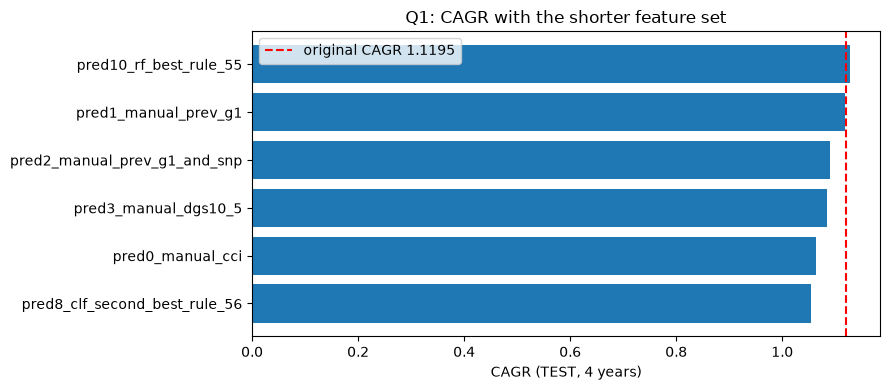

In [18]:
Q1_CAGR = float(df_sim1_results.set_index('prediction').loc['pred10_rf_best_rule_55', 'CAGR'])

print('Q1 answer: CAGR of pred10_rf_best_rule_55 =', round(Q1_CAGR, 4))
print('Original Colab CAGR (301 features) = 1.1195')
print('New CAGR is slightly higher:', Q1_CAGR > 1.1195)

top = df_sim1_results.head(6).iloc[::-1]
plt.figure(figsize=(9, 4))
plt.barh(top.prediction, top.CAGR)
plt.axvline(1.1195, color='red', linestyle='--', label='original CAGR 1.1195')
plt.xlabel('CAGR (TEST, 4 years)')
plt.title('Q1: CAGR with the shorter feature set')
plt.legend()
plt.tight_layout()
plt.show()

## Question 2: Most Efficient Random Forest Decision Rule

Build the `tpr_fpr_dataframe` with the **Random Forest** probabilities, then add rules for thresholds **0.56 … 0.64** (plus the existing `0.55` and `0.65`). Higher thresholds should give higher precision and fewer trades. Choose the rule with **average trades per day < 5** and the best CAGR.

In [19]:
X_test = clean_dataframe_from_inf_and_nan(
    new_df[new_df.split == 'test'][features_list + [to_predict]].copy(deep=True)
)
y_test = X_test[to_predict]
del X_test[to_predict]

y_pred_test_class1 = np.array([k[1] for k in rf_best.predict_proba(X_test)])

df_scores = tpr_fpr_dataframe(y_test, y_pred_test_class1, only_even=True)

print(df_scores[(df_scores.threshold >= 0.54) & (df_scores.threshold <= 0.66)]
      [['threshold', 'tp', 'fp', 'precision', 'recall', 'tpr', 'fpr']]
      .to_string(index=False))

 threshold   tp   fp  precision   recall      tpr      fpr
      0.54 2964 1949   0.603297 0.156776 0.156776 0.136705
      0.56 1664 1116   0.598561 0.088014 0.088014 0.078277
      0.58  916  603   0.603028 0.048450 0.048450 0.042295
      0.60  445  300   0.597315 0.023538 0.023538 0.021042
      0.62  218  131   0.624642 0.011531 0.011531 0.009188
      0.64  102   51   0.666667 0.005395 0.005395 0.003577
      0.66   32   19   0.627451 0.001693 0.001693 0.001333


In [20]:
# Existing rules
RF_RULES = {
    'pred10_rf_best_rule_55': 0.55,
    'pred11_rf_best_rule_65': 0.65,
}

# New thresholds 0.56 ... 0.64 (pred12 ... pred20)
for i, thr in enumerate([0.56, 0.57, 0.58, 0.59, 0.60, 0.61, 0.62, 0.63, 0.64], start=12):
    name = 'pred{}_rf_best_rule_{}'.format(i, int(round(thr * 100)))
    new_df[name] = (new_df['proba_rf'] >= thr).astype(int)
    RF_RULES[name] = thr

q2_rows = []
for name, thr in RF_RULES.items():
    row = run_simulation(new_df, name)
    row['threshold'] = thr
    q2_rows.append(row)

df_q2 = pd.DataFrame(q2_rows).sort_values('threshold').reset_index(drop=True)

print(df_q2[['threshold', 'prediction', 'trades', 'avg_inv_per_day', 'q75_inv_per_day', 'CAGR']]
      .to_string(index=False))

 threshold             prediction  trades  avg_inv_per_day  q75_inv_per_day     CAGR
      0.55 pred10_rf_best_rule_55    3756         6.058065              7.0 1.127955
      0.56 pred12_rf_best_rule_56    2780         5.346154              7.0 1.101405
      0.57 pred13_rf_best_rule_57    2086         4.851163              6.0 1.092026
      0.58 pred14_rf_best_rule_58    1519         4.494083              6.0 1.067167
      0.59 pred15_rf_best_rule_59    1090         4.325397              5.0 1.057452
      0.60 pred16_rf_best_rule_60     745         3.941799              4.0 1.049032
      0.61 pred17_rf_best_rule_61     522         3.600000              3.0 1.054272
      0.62 pred18_rf_best_rule_62     349         3.490000              3.0 1.033463
      0.63 pred19_rf_best_rule_63     229         3.094595              3.0 1.022911
      0.64 pred20_rf_best_rule_64     153         3.060000              3.0 1.017595
      0.65 pred11_rf_best_rule_65      92         3.285714       

In [21]:
eligible = df_q2[df_q2.avg_inv_per_day < 5].sort_values('CAGR', ascending=False)
print('Rules with average trades/day < 5:')
print(eligible[['threshold', 'prediction', 'trades', 'avg_inv_per_day', 'CAGR']].to_string(index=False))

best_q2 = eligible.iloc[0]
Q2_THRESHOLD = float(best_q2.threshold)
Q2_CAGR = float(best_q2.CAGR)
Q2_TRADES = int(best_q2.trades)
Q2_AVG_TRADES = float(best_q2.avg_inv_per_day)

print()
print('Q2 answer: threshold =', Q2_THRESHOLD)
print('           avg trades/day =', round(Q2_AVG_TRADES, 2))
print('           CAGR =', round(Q2_CAGR, 4))

Rules with average trades/day < 5:
 threshold             prediction  trades  avg_inv_per_day     CAGR
      0.57 pred13_rf_best_rule_57    2086         4.851163 1.092026
      0.58 pred14_rf_best_rule_58    1519         4.494083 1.067167
      0.59 pred15_rf_best_rule_59    1090         4.325397 1.057452
      0.61 pred17_rf_best_rule_61     522         3.600000 1.054272
      0.60 pred16_rf_best_rule_60     745         3.941799 1.049032
      0.62 pred18_rf_best_rule_62     349         3.490000 1.033463
      0.63 pred19_rf_best_rule_63     229         3.094595 1.022911
      0.64 pred20_rf_best_rule_64     153         3.060000 1.017595
      0.65 pred11_rf_best_rule_65      92         3.285714 1.009360

Q2 answer: threshold = 0.57
           avg trades/day = 4.85
           CAGR = 1.092


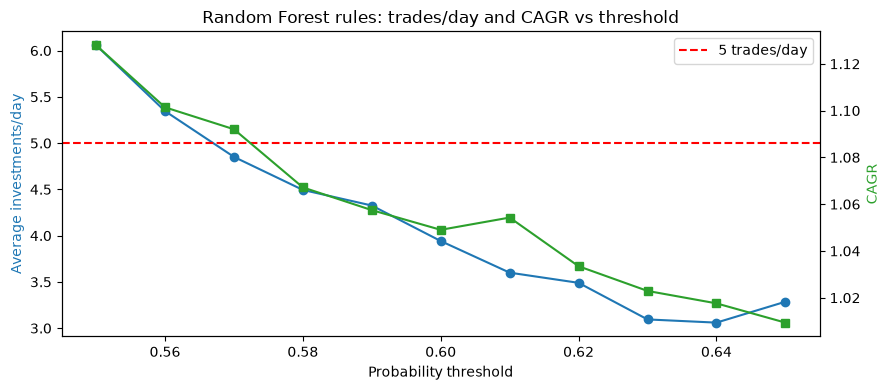

In [22]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(df_q2.threshold, df_q2.avg_inv_per_day, marker='o', color='tab:blue')
ax1.axhline(5, color='red', linestyle='--', label='5 trades/day')
ax1.set_xlabel('Probability threshold')
ax1.set_ylabel('Average investments/day', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(df_q2.threshold, df_q2.CAGR, marker='s', color='tab:green')
ax2.set_ylabel('CAGR', color='tab:green')

ax1.set_title('Random Forest rules: trades/day and CAGR vs threshold')
ax1.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Question 3: Redefining the Growth Target

Start from a fresh copy of the original notebook (full 301-feature setup). Redefine the target as:

```python
is_positive_growth_30d_future = (growth_future_30d > 1.022).astype(int)
```

This lowers the positive class from roughly 60% to roughly 50%. Retrain `clf_10` (`max_depth=10`) and count the trades of `pred5_clf_10`.

In [23]:
# Free the Q1/Q2 objects before building the full 301-feature dataset
del new_df, X_train_valid, X_all, y_train_valid, y_all, clf_best, rf_best
gc.collect()

CATEGORICAL_FULL = CATEGORICAL + ['month_wom']

dummy_variables_full = pd.get_dummies(df[CATEGORICAL_FULL], dtype='int32')
DUMMIES_FULL = dummy_variables_full.keys().to_list()
df_full_dummies = pd.concat([df, dummy_variables_full], axis=1)

features_full = NUMERICAL + DUMMIES_FULL

print('Dummy variables (full):', len(DUMMIES_FULL))
print('Total features:', len(features_full), '(expected 301)')

Dummy variables (full): 115
Total features: 301 (expected 301)


In [24]:
new_df_full = df_full_dummies.copy()

# hand rules (same as the Colab)
new_df_full['pred0_manual_cci'] = (new_df_full.cci > 200).astype(int)
new_df_full['pred1_manual_prev_g1'] = (new_df_full.growth_30d > 1).astype(int)
new_df_full['pred2_manual_prev_g1_and_snp'] = ((new_df_full.growth_30d > 1) & (new_df_full.growth_snp500_30d > 1)).astype(int)
new_df_full['pred3_manual_dgs10_5'] = ((new_df_full.DGS10 <= 4.5) & (new_df_full.DGS5 <= 4)).astype(int)
new_df_full['pred4_manual_dgs10_fedfunds'] = ((new_df_full.DGS10 > 4) & (new_df_full.FEDFUNDS <= 4.795)).astype(int)

new_df_full = temporal_split(new_df_full, new_df_full.Date.min(), new_df_full.Date.max())

print('growth_future_30d:')
print(new_df_full.growth_future_30d.describe().round(3))

print()
print('Share of class 1 with the ORIGINAL target (growth > 1)  :',
      round(float((new_df_full.growth_future_30d > 1).mean()), 4))
print('Share of class 1 with the NEW target (growth > 1.022)     :',
      round(float((new_df_full.growth_future_30d > 1.022).mean()), 4))

growth_future_30d:
count    201302.000
mean          1.023
std           0.116
min           0.246
25%           0.961
50%           1.021
75%           1.082
max           5.180
Name: growth_future_30d, dtype: float64

Share of class 1 with the ORIGINAL target (growth > 1)  : 0.5895
Share of class 1 with the NEW target (growth > 1.022)     : 0.4912


In [25]:
# Baseline sanity check: pred5 with the ORIGINAL target (> 1), full 301 features
train_valid_df = new_df_full[new_df_full.split.isin(['train', 'validation'])].copy(deep=True)

X_train_valid = clean_dataframe_from_inf_and_nan(train_valid_df[features_full + [to_predict]].copy(deep=True))
X_all_full = clean_dataframe_from_inf_and_nan(new_df_full[features_full + [to_predict]].copy(deep=True))

y_train_valid = X_train_valid[to_predict]
del X_train_valid[to_predict]
del X_all_full[to_predict]

clf_10_base = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
clf_10_base.fit(X_train_valid, y_train_valid)

new_df_full['pred5_base'] = clf_10_base.predict(X_all_full)

base_sim = run_simulation(new_df_full, 'pred5_base')
print('Baseline pred5 (target > 1): trades =', base_sim['trades'],
      '| avg/day =', round(base_sim['avg_inv_per_day'], 2),
      '| CAGR =', round(base_sim['CAGR'], 4))

Baseline pred5 (target > 1): trades = 9861 | avg/day = 10.26 | CAGR = 1.1196


In [26]:
# Redefine the target and rebuild the split
new_df_full[to_predict] = (new_df_full.growth_future_30d > 1.022).astype(int)
print('New target mean:', round(float(new_df_full[to_predict].mean()), 4))

new_df_full = temporal_split(new_df_full, new_df_full.Date.min(), new_df_full.Date.max())

train_valid_df = new_df_full[new_df_full.split.isin(['train', 'validation'])].copy(deep=True)

X_train_valid = clean_dataframe_from_inf_and_nan(train_valid_df[features_full + [to_predict]].copy(deep=True))
X_all_full = clean_dataframe_from_inf_and_nan(new_df_full[features_full + [to_predict]].copy(deep=True))

y_train_valid = X_train_valid[to_predict]
y_all = X_all_full[to_predict]
del X_train_valid[to_predict]
del X_all_full[to_predict]

clf_10 = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
clf_10.fit(X_train_valid, y_train_valid)

new_df_full['pred5_clf_10'] = clf_10.predict(X_all_full)

print('clf_10 trained with the new target.')

New target mean: 0.4912


clf_10 trained with the new target.


In [27]:
PRED3 = [k for k in new_df_full.keys() if k.startswith('pred') and k != 'pred5_base']

df_q3 = pd.DataFrame([run_simulation(new_df_full, p) for p in PRED3])
df_q3 = df_q3.sort_values('CAGR', ascending=False).reset_index(drop=True)

print(df_q3[['prediction', 'trades', 'avg_inv_per_day', 'capital', 'net_rev', 'CAGR']]
      .to_string(index=False))

row3 = df_q3.set_index('prediction').loc['pred5_clf_10']
Q3_TRADES = int(row3.trades)
Q3_AVG_TRADES = float(row3.avg_inv_per_day)
Q3_CAGR = float(row3.CAGR)

print()
print('Q3 answer: trades of pred5_clf_10 =', Q3_TRADES)
print('           avg trades/day =', round(Q3_AVG_TRADES, 2))
print('           CAGR =', round(Q3_CAGR, 4))

                  prediction  trades  avg_inv_per_day  capital      net_rev     CAGR
                pred5_clf_10    7337         8.009825  30000.0 17531.155557 1.121926
        pred1_manual_prev_g1   19158        18.421154  72000.0 40918.366885 1.119072
pred2_manual_prev_g1_and_snp   15244        21.715100  75000.0 30853.894246 1.089962
        pred3_manual_dgs10_5   15910        31.947791  99000.0 37541.803021 1.083696
            pred0_manual_cci     921         1.875764   6000.0  1656.192853 1.062834
 pred4_manual_dgs10_fedfunds   15921        31.905812  99000.0 15546.679990 1.037139

Q3 answer: trades of pred5_clf_10 = 7337
           avg trades/day = 8.01
           CAGR = 1.1219


## Question 4: [EXPLORATORY] Describe Your Ideal Trading Strategy

**Confidence-weighted, concentrated and risk-limited.**

1. **Signal.** Use the Random Forest probability `p = P(growth_30d > 1 | X)` as the main signal. Only trade names with `p >= 0.60`: precision stays around 60% but the number of trades falls sharply compared with the 0.55 rule.
2. **Position sizing.** Instead of investing $100 on every positive prediction, rank the daily candidates by `p` and allocate the daily budget to the **top 3–5 names**, with weights proportional to `(p - 0.55)` (or equal weights). Cap each position at 25–30% of the daily budget.
3. **Fewer trades / lower costs.** Skip a name if it already has an open position from the previous 30 days, and avoid extreme-volatility or low-liquidity names. This reduces turnover and the 0.2% round-trip fees.
4. **Risk management.** Keep 30–40% cash, limit to at most 2 names per `ticker_type`, and stop adding to a position after a 10% drawdown. Rebalance once a day at the close and hold for 30 calendar days.

Expected effect: a CAGR close to the best threshold rule, but with fewer, larger and better-ranked bets, lower fees and less capital tied up.

## Answers summary

| Question | Answer |
|---|---|
| Q1 | CAGR of `pred10_rf_best_rule_55` with 208 features = **1.128** (original 1.1195) |
| Q2 | Second-best Random Forest rule with < 5 trades/day: threshold = **0.57** (4.85 trades/day, CAGR 1.092) |
| Q3 | Trades of `pred5_clf_10` with target `growth_future_30d > 1.022` = **7,337** (8.01 trades/day, CAGR 1.122; baseline with target > 1: 9,861 trades) |
| Q4 | Ideal strategy described above (exploratory) |

In [28]:
print('=' * 72)
print('Q1  CAGR pred10_rf_best_rule_55 (208 features) =', round(Q1_CAGR, 4), '(original 1.1195)')
print('Q2  best RF rule with <5 trades/day          =', Q2_THRESHOLD,
      '| CAGR =', round(Q2_CAGR, 4))
print('Q3  trades pred5_clf_10 (target > 1.022)     =', Q3_TRADES,
      '| CAGR =', round(Q3_CAGR, 4))
print('Q4  ideal strategy: described above')
print('=' * 72)

Q1  CAGR pred10_rf_best_rule_55 (208 features) = 1.128 (original 1.1195)
Q2  best RF rule with <5 trades/day          = 0.57 | CAGR = 1.092
Q3  trades pred5_clf_10 (target > 1.022)     = 7337 | CAGR = 1.1219
Q4  ideal strategy: described above
